<a href="https://colab.research.google.com/github/sravyam230/bcg-data-science-churn-analysis-sim/blob/main/bcg_data_science_churn_analysis_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PowerCo customer churn

BCG X Data Science Job Simulation (Forage), February 2026.

PowerCo is a gas and electricity supplier to small and medium-sized businesses. Customers have been leaving for other providers, and PowerCo's working theory is that they are price sensitive: that churn is driven by price. The job is to test that theory, build a model that predicts which customers will churn, and say what actually drives it.

**Outline**
1. Framing the problem
2. The data
3. Exploratory data analysis
4. Feature engineering
5. Modelling and evaluation
6. Findings and recommendations

The datasets are provided by Forage for simulation use only and are not included in this repository.

## 1. Framing the problem

Before touching the data, the first task was an email to the client setting out what would be needed to test the price-sensitivity hypothesis. In short:

- **Other reasons a customer might leave** that have to be controlled for: contract type and renewal terms, tariff structure, energy source, service quality, billing problems, competitor offers.
- **Data requested**: customer profile and tenure, contract and pricing history (unit prices, standing charges, discounts), consumption and billing history, and a churn flag.
- **Approach**: understand the business, explore and clean the data, engineer features that capture price changes over time, train a classifier that can report which variables matter, and translate the result into recommendations.

Price sensitivity is measured in economics as price elasticity of demand (percentage change in quantity demanded divided by percentage change in price). Here the proxy is simpler: does the price a customer pays, and how it has changed, predict whether they churn?

## 2. The data

PowerCo sent two tables.

- `client_data.csv`: one row per customer (14,606), with consumption over the last 12 months and last month, forecast consumption and prices, margins, number of products, tenure, sales channel, and the churn flag.
- `price_data.csv`: one row per customer per month for 2015 (193,002 rows), with variable and fixed prices for off-peak, peak and mid-peak periods.

The categorical columns (`channel_sales`, `origin_up`) are hashed, so they can be used as categories but not interpreted.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

client_data = pd.read_csv("client_data.csv")
price_data = pd.read_csv("price_data.csv")

print("Client data shape:", client_data.shape)
print("Price data shape:", price_data.shape)

Client data shape: (14606, 26)
Price data shape: (165631, 8)


## 3. Exploratory data analysis

### 3.1 First look

In [59]:
client_data.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,0,0.0,19.83,0.146694,0.000000,44.311378,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,526,0.0,131.73,0.116900,0.100015,40.606701,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


In [60]:
price_data.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [61]:
client_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [62]:
# Convert date columns so they can be used later
for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]:
    client_data[col] = pd.to_datetime(client_data[col], errors="coerce")
price_data["price_date"] = pd.to_datetime(price_data["price_date"])

### 3.2 Descriptive statistics

In [63]:
client_data.describe().T

,count,mean,min,25%,50%,75%,max,std
cons_12m,14606.0,159220.286252,0.0,5674.75,14115.5,40763.75,6207104.0,573465.264198
cons_gas_12m,14606.0,28092.375325,0.0,0.0,0.0,0.0,4154590.0,162973.059057
cons_last_month,14606.0,16090.269752,0.0,0.0,792.5,3383.0,771203.0,64364.196422
date_activ,14606,2011-01-28 07:54:18.879912448,2003-05-09 00:00:00,2010-01-15 00:00:00,2011-03-04 00:00:00,2012-04-19 00:00:00,2014-09-01 00:00:00,NaN
date_end,14606,2016-07-27 20:48:26.422018560,2016-01-28 00:00:00,2016-04-27 06:00:00,2016-08-01 00:00:00,2016-10-31 00:00:00,2017-06-13 00:00:00,NaN
date_modif_prod,14606,2013-01-02 12:29:10.951663872,2003-05-09 00:00:00,2010-08-12 00:00:00,2013-06-19 00:00:00,2015-06-16 00:00:00,2016-01-29 00:00:00,NaN
date_renewal,14606,2015-07-21 06:59:00.353279488,2013-06-26 00:00:00,2015-04-17 00:00:00,2015-07-27 00:00:00,2015-10-29 00:00:00,2016-01-28 00:00:00,NaN
forecast_cons_12m,14606.0,1868.61488,0.0,494.995,1112.875,2401.79,82902.83,2387.571531
forecast_cons_year,14606.0,1399.762906,0.0,0.0,314.0,1745.75,175375.0,3247.786255
forecast_discount_energy,14606.0,0.966726,0.0,0.0,0.0,0.0,30.0,5.108289


In [64]:
price_data.describe().T

,count,mean,min,25%,50%,75%,max,std
price_date,165630,2015-06-16 12:55:18.181488896,2015-01-01 00:00:00,2015-04-01 00:00:00,2015-07-01 00:00:00,2015-10-01 00:00:00,2015-12-01 00:00:00,NaN
price_off_peak_var,165630.0,0.140987,0.0,0.125976,0.146033,0.151635,0.2807,0.025062
price_peak_var,165630.0,0.054755,0.0,0.0,0.085483,0.10178,0.196782,0.049926
price_mid_peak_var,165630.0,0.030704,0.0,0.0,0.0,0.072612,0.114102,0.036343
price_off_peak_fix,165630.0,43.335025,0.0,40.728885,44.26693,44.44471,59.44471,5.402233
price_peak_fix,165630.0,10.692696,0.0,0.0,0.0,24.339581,36.490692,12.852089
price_mid_peak_fix,165630.0,6.454632,0.0,0.0,0.0,16.226389,17.458221,7.782601


In [65]:
client_data.describe(include="object").T

,count,unique,top,freq
id,14606,14606,24011ae4ebbe3035111d65fa7c15bc57,1
channel_sales,14606,8,foosdfpfkusacimwkcsosbicdxkicaua,6754
has_gas,14606,2,f,11955
origin_up,14606,6,lxidpiddsbxsbosboudacockeimpuepw,7097


In [66]:
# How many distinct values each column has
client_data.nunique().sort_values()

,0
churn,2
has_gas,2
origin_up,6
channel_sales,8
nb_prod_act,10
forecast_discount_energy,12
num_years_antig,13
forecast_price_pow_off_peak,41
forecast_price_energy_peak,329
date_end,368


### 3.3 Missing values

Client data missing values: 0
Price data missing values: 7


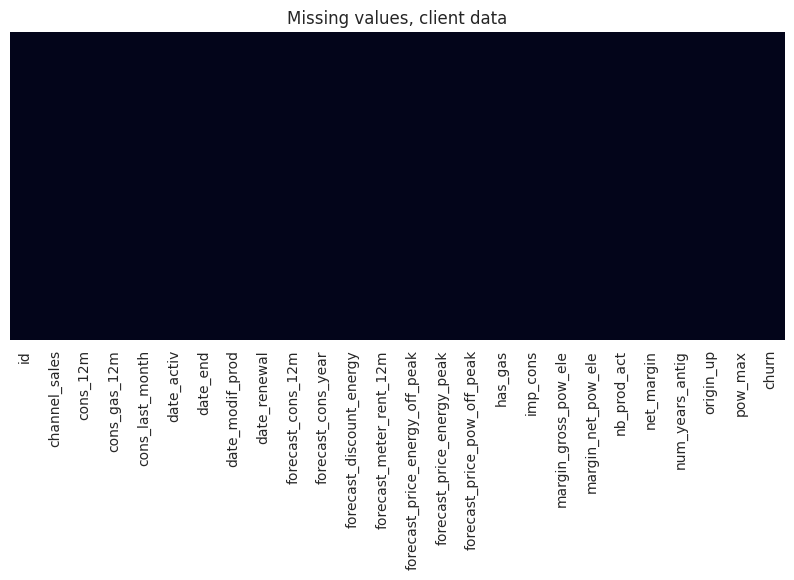

In [67]:
print("Client data missing values:", client_data.isnull().sum().sum())
print("Price data missing values:", price_data.isnull().sum().sum())
plt.figure(figsize=(10, 4))
sns.heatmap(client_data.isnull(), cbar=False, yticklabels=False)
plt.title("Missing values, client data")
plt.show()

No missing values in the client table and seven in the price table (out of 193,002 rows), which are ignored when prices are averaged per customer in section 4. `channel_sales` and `origin_up` use the string `MISSING` as a category rather than a null, which is handled as its own category later.

### 3.4 Churn rate

Churn rate: 9.7%


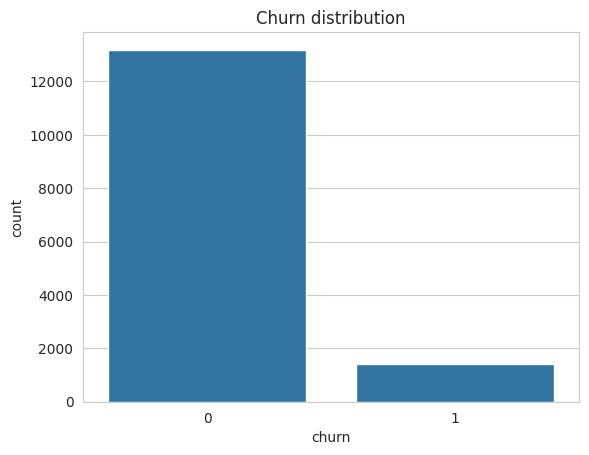

In [68]:
churn_rate = client_data["churn"].mean()
print(f"Churn rate: {churn_rate:.1%}")

sns.countplot(x="churn", data=client_data)
plt.title("Churn distribution")
plt.show()

About 10% of customers churned. That is a low rate in absolute terms, but it means the classes are imbalanced: a model that predicts "no churn" for everyone would be 90% accurate and useless, which decides how the model is evaluated in section 5.

### 3.5 Distributions of numeric columns

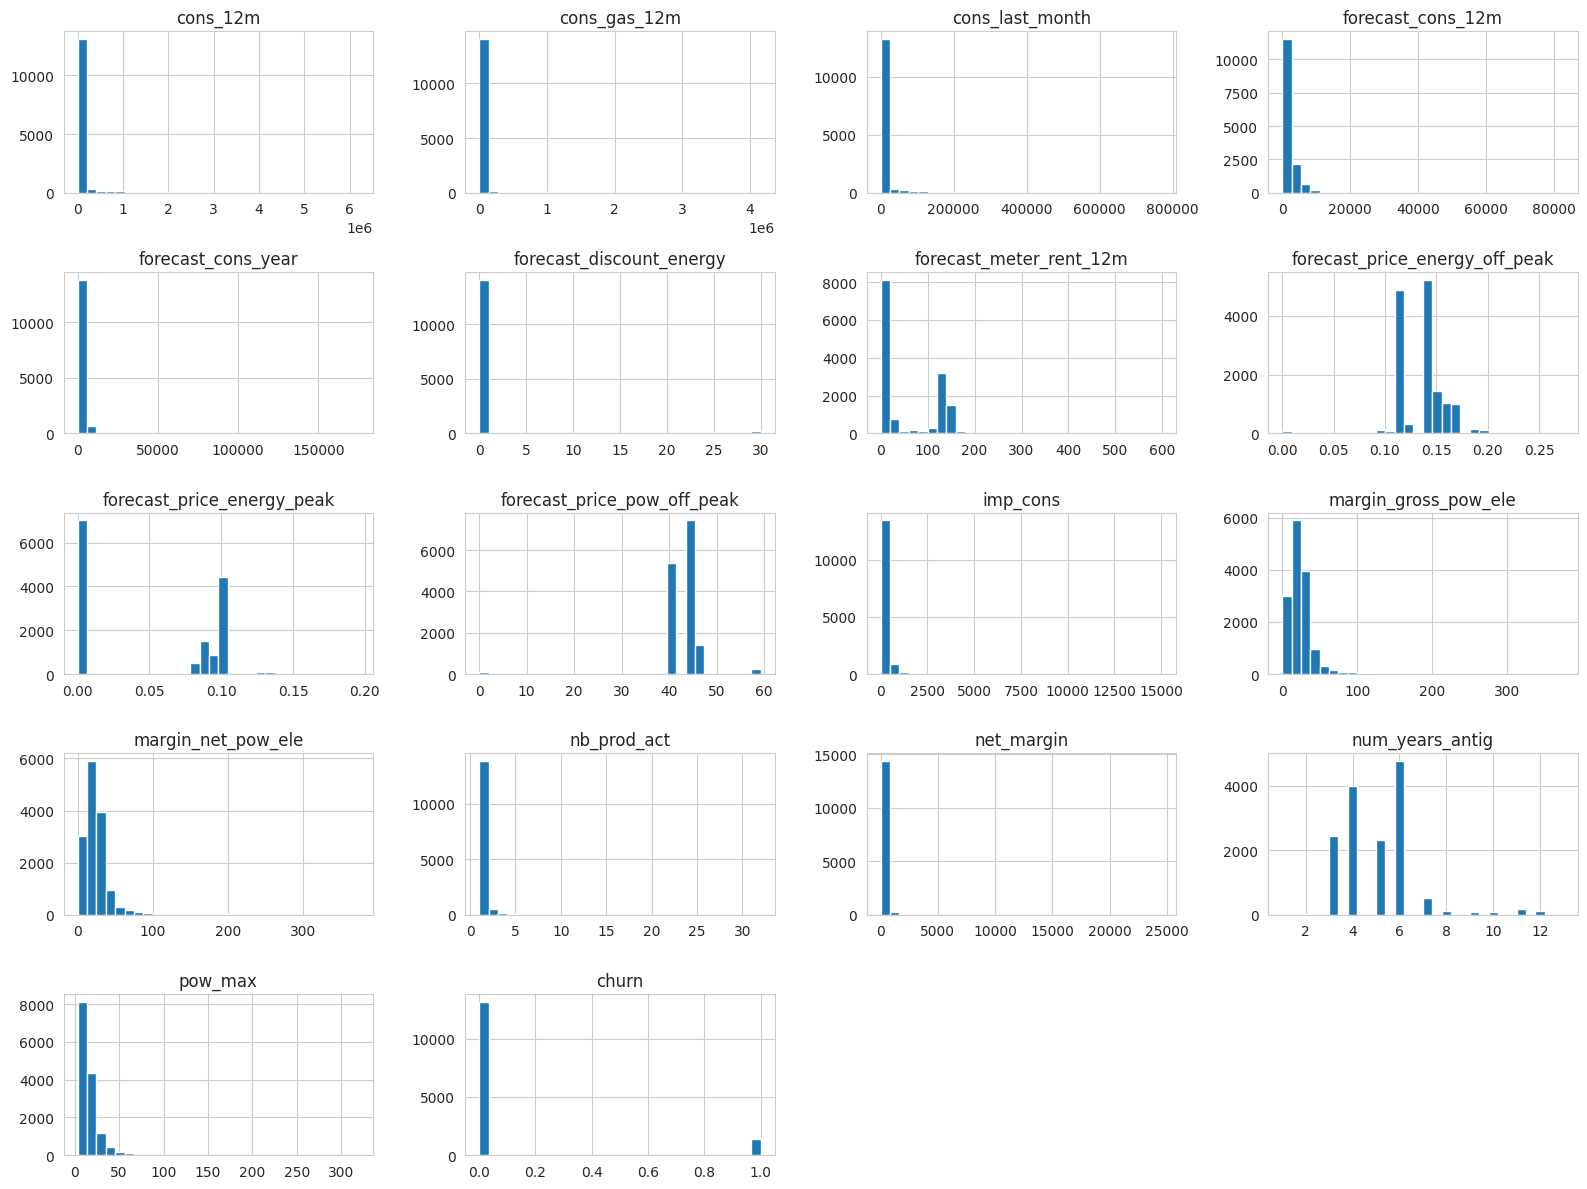

In [69]:
numeric_cols = client_data.select_dtypes(include=np.number).columns
client_data[numeric_cols].hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

Consumption, forecasts and margins are all heavily right-skewed with long tails, so they will need a log transform before modelling. Several columns (`forecast_discount_energy`, `cons_gas_12m`) are mostly zeros.

### 3.6 Prices over time

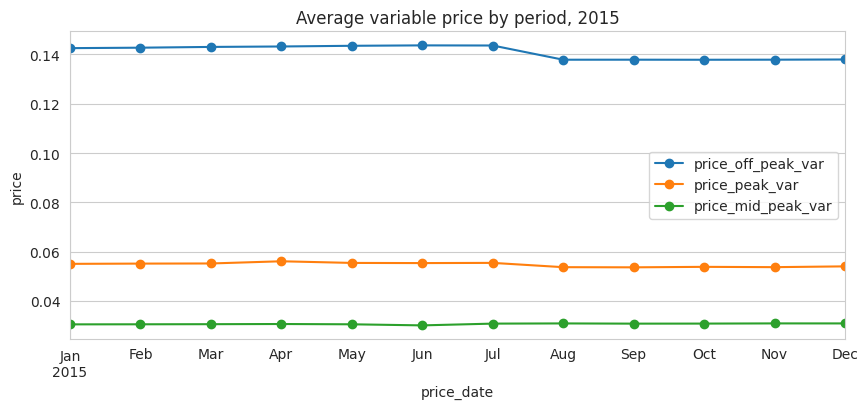

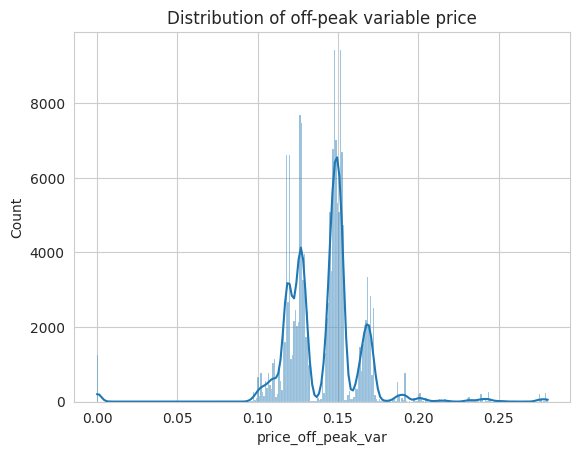

In [70]:
# Average price across all customers per month
monthly = price_data.groupby("price_date")[["price_off_peak_var", "price_peak_var", "price_mid_peak_var"]].mean()
monthly.plot(figsize=(10, 4), marker="o")
plt.title("Average variable price by period, 2015")
plt.ylabel("price")
plt.show()

sns.histplot(price_data["price_off_peak_var"], kde=True)
plt.title("Distribution of off-peak variable price")
plt.show()

Average prices moved very little during the year. Whatever is driving churn, it is not a large across-the-board price rise.

### 3.7 Does price differ between churners and non-churners?

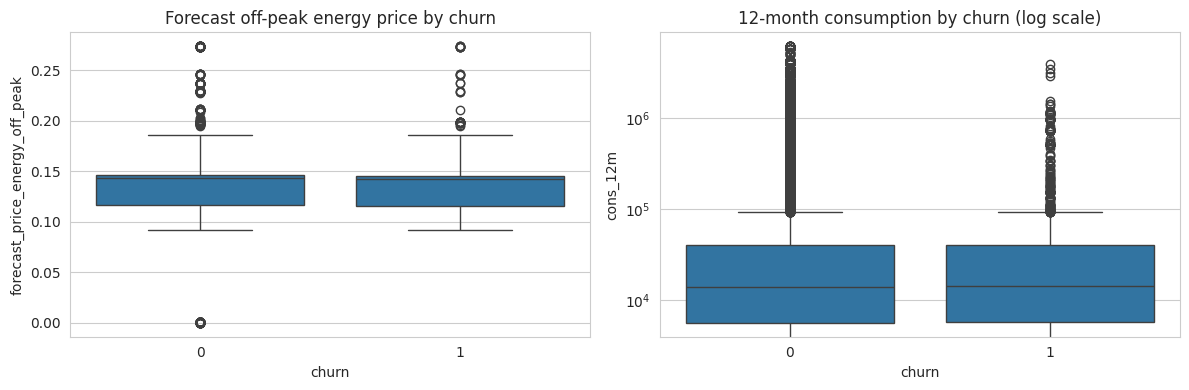

,forecast_price_energy_off_peak,forecast_price_energy_peak,cons_12m,net_margin,num_years_antig
churn,,,,,
0,0.143227,0.083909,14075.0,111.86,5.0
1,0.142819,0.086803,14529.0,121.86,4.0


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="churn", y="forecast_price_energy_off_peak", data=client_data, ax=axes[0])
axes[0].set_title("Forecast off-peak energy price by churn")
sns.boxplot(x="churn", y="cons_12m", data=client_data, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("12-month consumption by churn (log scale)")
plt.tight_layout()
plt.show()

client_data.groupby("churn")[["forecast_price_energy_off_peak", "forecast_price_energy_peak", "cons_12m", "net_margin", "num_years_antig"]].median()

The forecast price distributions for churners and non-churners sit almost on top of each other. Consumption, margin and tenure show more separation than price does, which is the first sign that the price-sensitivity hypothesis is incomplete.

### 3.8 Correlations

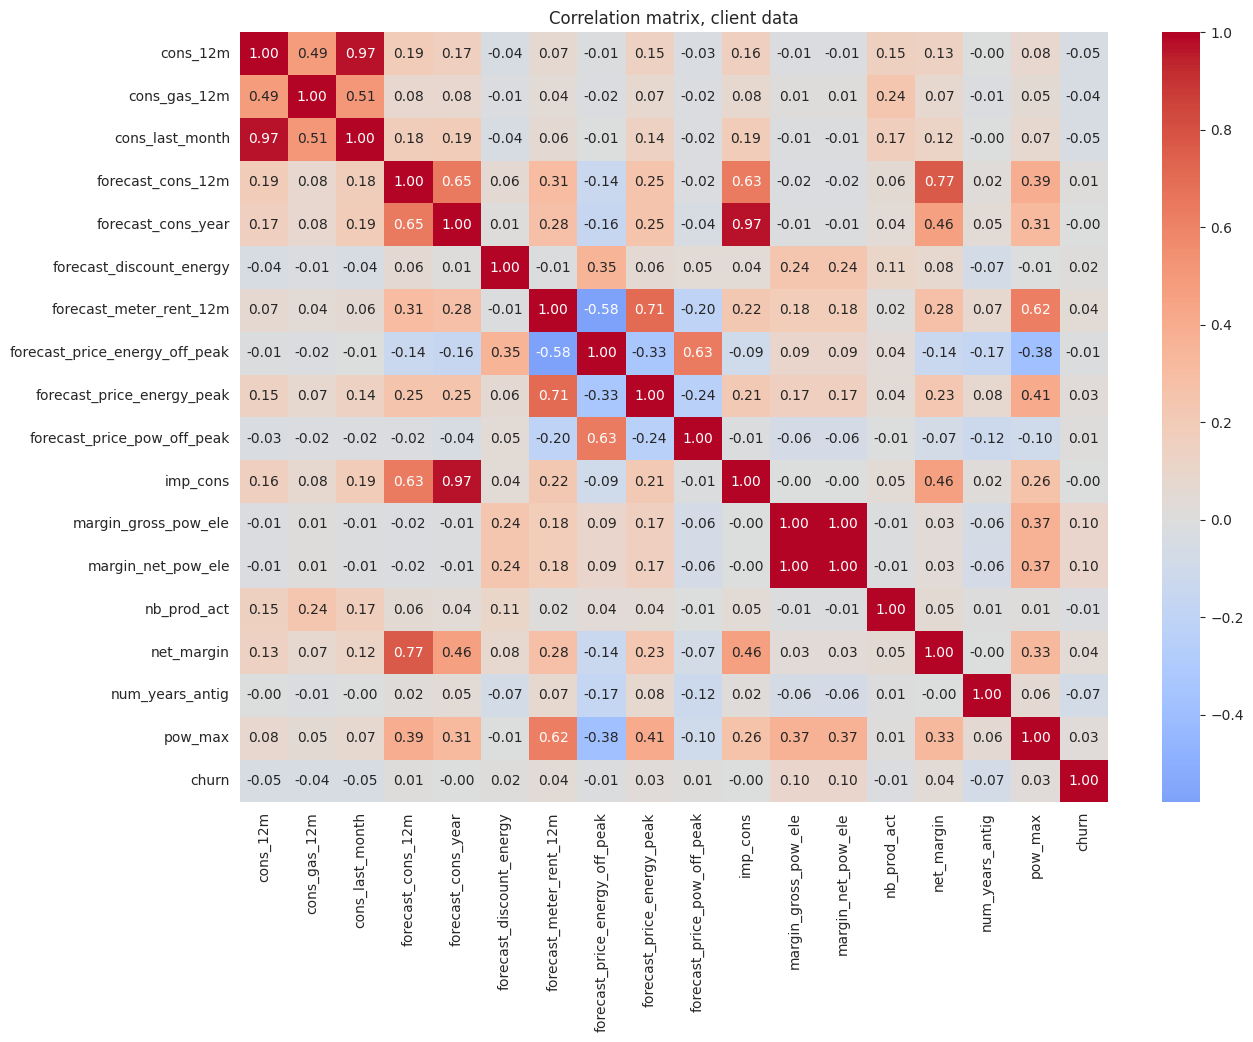

In [72]:
plt.figure(figsize=(14, 10))
sns.heatmap(client_data.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix, client data")
plt.show()

`num_years_antig` and `forecast_cons_year` are strongly correlated with other columns, so one of each pair can be dropped later. Nothing correlates strongly with `churn` on its own, which is normal for this kind of problem and why a model is needed.

## 4. Feature engineering

The cleaned client table from the EDA stage (`clean_data_after_eda.csv`) is the starting point, joined to the price history. The aim is to turn raw columns into variables that could plausibly explain churn, especially ones that capture *changes* in price over the year, since a stable price is unlikely to drive anyone away.

In [73]:
df = pd.read_csv("clean_data_after_eda.csv")
for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]:
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")
price_df = pd.read_csv("price_data.csv")
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format="%Y-%m-%d")
df.shape

(14606, 44)

### 4.1 Off-peak price change, December vs January

A colleague on the case suggested that the change in off-peak price between January and December could predict churn. This starter code was provided with the task.

In [74]:
# Group off-peak prices by companies and month
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()

# Get january and december prices
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()

# Calculate the difference
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy','offpeak_diff_dec_january_power']]

df = pd.merge(df, diff, on="id")
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,var_year_price_off_peak_var,var_year_price_peak_var,var_year_price_mid_peak_var,var_year_price_off_peak_fix,var_year_price_peak_fix,var_year_price_mid_peak_fix,var_year_price_off_peak,var_year_price_peak,var_year_price_mid_peak,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,0.000061,2.627605e-05,0.00044,1.102785,49.550703,22.022535,1.102846,4.955073e+01,22.022975,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1,0.020057,3.700961
1,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0.000006,2.558511e-07,0.00000,0.007662,0.000000,0.000000,0.007668,2.558511e-07,0.000000,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0,-0.004670,0.177779
2,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,0,0.0,19.83,0.146694,0.000000,44.311378,f,0.0,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0.000005,0.000000e+00,0.00000,0.006465,0.000000,0.000000,0.006470,0.000000e+00,0.000000,0.000003,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000003,0.000000e+00,0.000000,0,-0.004547,0.177779


### 4.2 Price gaps between periods

**Target:** one row per customer with the average difference between off-peak and peak price, and between peak and mid-peak price, for both the variable (energy) and fixed (power) components. Merge onto `df` by `id`.

Reasoning to write in your own words afterwards: why a gap between periods might annoy a customer more than the level of the price.

In [75]:
# Average each customer's six price columns over 2015
price_cols = [
    "price_off_peak_var", "price_peak_var", "price_mid_peak_var",
    "price_off_peak_fix", "price_peak_fix", "price_mid_peak_fix",
]
avg_prices = price_df.groupby("id")[price_cols].mean()

gaps = pd.DataFrame({
    "gap_offpeak_peak_var": avg_prices["price_off_peak_var"] - avg_prices["price_peak_var"],
    "gap_peak_midpeak_var": avg_prices["price_peak_var"] - avg_prices["price_mid_peak_var"],
    "gap_offpeak_peak_fix": avg_prices["price_off_peak_fix"] - avg_prices["price_peak_fix"],
    "gap_peak_midpeak_fix": avg_prices["price_peak_fix"] - avg_prices["price_mid_peak_fix"],
}).reset_index()

df = df.merge(gaps, on="id", how="left")
print("Customers with no price history:", df["gap_offpeak_peak_var"].isna().sum())


Customers with no price history: 0


### 4.3 Largest monthly price jump

**Target:** for each customer, the maximum month-to-month change in each price gap from 4.2 across 2015. Merge onto `df`.

Hint: compute the gaps per customer per month first, then `groupby('id').max()`.

In [76]:
# Month-by-month gap for each customer, then the largest month-to-month increase
gap_cols = ["gap_offpeak_peak_var", "gap_peak_midpeak_var", "gap_offpeak_peak_fix", "gap_peak_midpeak_fix"]

monthly = price_df.sort_values(["id", "price_date"]).copy()
monthly["gap_offpeak_peak_var"] = monthly["price_off_peak_var"] - monthly["price_peak_var"]
monthly["gap_peak_midpeak_var"] = monthly["price_peak_var"] - monthly["price_mid_peak_var"]
monthly["gap_offpeak_peak_fix"] = monthly["price_off_peak_fix"] - monthly["price_peak_fix"]
monthly["gap_peak_midpeak_fix"] = monthly["price_peak_fix"] - monthly["price_mid_peak_fix"]

jump_cols = []
for g in gap_cols:
    jump = f"max_jump_{g}"
    monthly[jump] = monthly.groupby("id")[g].diff()   # change from the previous month
    jump_cols.append(jump)

max_jumps = monthly.groupby("id")[jump_cols].max().reset_index()
df = df.merge(max_jumps, on="id", how="left")
print(df[jump_cols].describe().T[["mean", "50%", "max"]])


                                   mean       50%        max
max_jump_gap_offpeak_peak_var  0.006229  0.000013   0.219165
max_jump_gap_peak_midpeak_var  0.005310  0.000000   0.117311
max_jump_gap_offpeak_peak_fix  1.015256  0.065166  44.444710
max_jump_gap_peak_midpeak_fix  0.228586  0.000000  28.122958


### 4.4 Tenure and time-based features

**Target:** using a reference date of 1 January 2016, create `tenure` in years (from `date_activ` to `date_end`), and `months_activ`, `months_to_end`, `months_modif_prod`, `months_renewal` as whole months between each date and the reference date. Then drop the four raw date columns.

Check: `df.groupby('tenure')['churn'].mean()` should show whether short-tenure customers churn more.

In [77]:
REFERENCE_DATE = pd.Timestamp("2016-01-01")

def months_before_ref(s):
    """Whole months from the date in s up to the reference date (positive if s is earlier)."""
    return (REFERENCE_DATE.year - s.dt.year) * 12 + (REFERENCE_DATE.month - s.dt.month)

def months_after_ref(s):
    """Whole months from the reference date to the date in s (negative if s is earlier)."""
    return (s.dt.year - REFERENCE_DATE.year) * 12 + (s.dt.month - REFERENCE_DATE.month)

df["tenure"] = (df["date_end"] - df["date_activ"]).dt.days // 365   # whole years under contract
df["months_activ"] = months_before_ref(df["date_activ"])
df["months_to_end"] = months_after_ref(df["date_end"])
df["months_modif_prod"] = months_before_ref(df["date_modif_prod"])
df["months_renewal"] = months_before_ref(df["date_renewal"])

df = df.drop(columns=["date_activ", "date_end", "date_modif_prod", "date_renewal"])

print(df.groupby("tenure")["churn"].agg(["mean", "size"]))


            mean  size
tenure                
2       0.180000    50
3       0.148637  1137
4       0.129596  3264
5       0.088898  2486
6       0.076845  2954
7       0.076741  2111
8       0.056604   106
9       0.000000    65
10      0.052632    38
11      0.060976   164
12      0.090090   111
13      0.111111    36


### 4.5 Encoding and transforms

**Targets:**
- `has_gas`: map `t`/`f` to 1/0.
- `channel_sales` and `origin_up`: one-hot encode, after grouping categories with fewer than 100 customers into a single `other` bucket.
- Skewed columns (`cons_12m`, `cons_gas_12m`, `cons_last_month`, `forecast_cons_12m`, `forecast_cons_year`, `forecast_meter_rent_12m`, `imp_cons`): apply `np.log10(x + 1)` and show a before/after histogram for one of them.
- Drop `num_years_antig` and `forecast_cons_year` (correlated with other columns, see 3.8).

Finish with `df.shape` and `df.head()`.

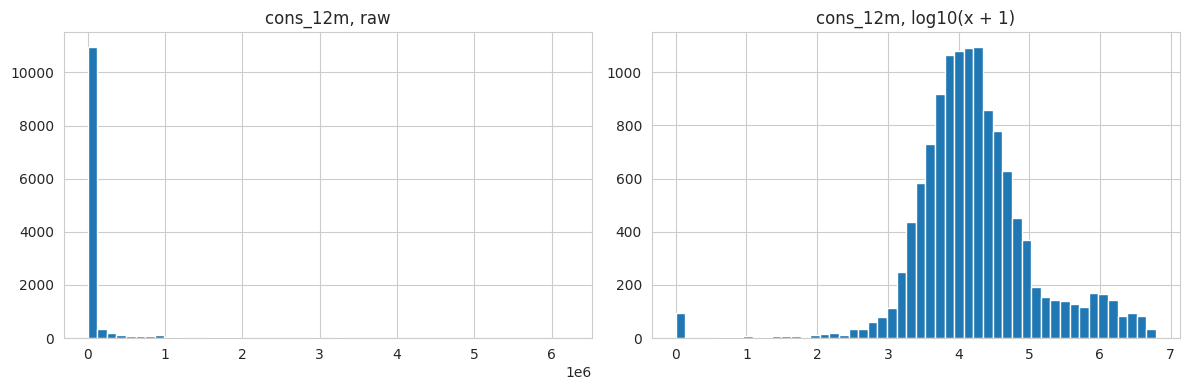

(12522, 61)


,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,pow_max,var_year_price_off_peak_var,var_year_price_peak_var,var_year_price_mid_peak_var,var_year_price_off_peak_fix,var_year_price_peak_fix,var_year_price_mid_peak_fix,var_year_price_off_peak,var_year_price_peak,var_year_price_mid_peak,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,gap_offpeak_peak_var,gap_peak_midpeak_var,gap_offpeak_peak_fix,gap_peak_midpeak_fix,max_jump_gap_offpeak_peak_var,max_jump_gap_peak_midpeak_var,max_jump_gap_offpeak_peak_fix,max_jump_gap_peak_midpeak_fix,tenure,months_activ,months_to_end,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_other,channel_usilxuppasemubllopkaafesmlibmsdf,origin_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_ldkssxwpmemidmecebumciepifcamkci,origin_lxidpiddsbxsbosboudacockeimpuepw,origin_other
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,1,0.000000,25.44,25.44,2,678.99,43.648,0.000061,2.627605e-05,0.000440,1.102785,49.550703,22.022535,1.102846,4.955073e+01,22.022975,0.000131,4.100838e-05,9.084737e-04,2.086294,99.530517,44.235794,2.086425,9.953056e+01,4.423670e+01,1,0.020057,3.700961,0.024038,0.034219,18.590255,7.450670,0.042865,0.059508,27.975375,0.032580,3,31,5,2,7,0,0,1,0,0,0,0,0,1,0
1,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,0,0.000000,28.60,28.60,1,6.60,13.856,0.000006,2.558511e-07,0.000000,0.007662,0.000000,0.000000,0.007668,2.558511e-07,0.000000,0.000004,9.450150e-08,0.000000e+00,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000e+00,0,-0.004670,0.177779,0.082090,0.088421,44.385450,0.000000,0.000000,0.001281,0.177779,0.000000,6,69,3,69,9,0,0,1,0,0,0,1,0,0,0
2,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,0,0.000000,30.22,30.22,1,25.46,13.200,0.000005,0.000000e+00,0.000000,0.006465,0.000000,0.000000,0.006470,0.000000e+00,0.000000,0.000003,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000003,0.000000e+00,0.000000e+00,0,-0.004547,0.177779,0.151210,0.000000,44.400265,0.000000,0.000000,0.000000,0.177779,0.000000,6,70,2,70,10,0,0,0,1,0,0,1,0,0,0
3,7ab4bf4878d8f7661dfc20e9b8e18011,4.654157,0.000000,0.000000,3.906889,0.0,0.000000,0.166178,0.087538,44.311378,0,0.000000,4.04,4.04,1,346.63,15.000,0.000006,1.503433e-07,0.000000,0.000000,0.000000,0.000000,0.000006,1.503433e-07,0.000000,0.000004,9.450150e-08,0.000000e+00,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000e+00,1,-0.004628,0.000000,0.081316,0.084744,44.266930,0.000000,0.000000,0.000000,0.000000,0.000000,5,49,11,49,1,0,0,1,0,0,0,0,0,1,0
4,01495c955be7ec5e7f3203406785aae0,4.470602,0.000000,3.100715,2.937382,0.0,2.162833,0.115174,0.098837,40.606701,0,1.855095,53.92,53.92,1,100.09,26.400,0.000017,3.398299e-06,0.000002,0.006434,0.002316,0.001029,0.006451,2.319747e-03,0.001032,0.000011,2.896760e-06,4.860000e-10,0.000000,0.000000,0.000000,0.000011,2.896760e-06,4.860000e-10,0,-0.007801,0.162916,0.020314,0.028965,16.269833,8.134914,0.000000,0.000000,0.065166,0.032583,6,69,3,69,9,0,0,1,0,0,0,0,0,1,0


In [78]:
# 1. Gas flag: t/f -> 1/0
df["has_gas"] = df["has_gas"].map({"t": 1, "f": 0})

# 2. Group categories with fewer than 100 customers into 'other', then one-hot encode
for col in ["channel_sales", "origin_up"]:
    counts = df[col].value_counts()
    rare = counts[counts < 100].index
    df[col] = df[col].where(~df[col].isin(rare), "other")
df = pd.get_dummies(df, columns=["channel_sales", "origin_up"], prefix=["channel", "origin"], dtype=int)

# 3. Log-transform the skewed columns, with a before/after histogram for cons_12m
# forecast_cons_year is dropped in step 4, so it is not transformed.
skewed = [
    "cons_12m", "cons_gas_12m", "cons_last_month", "forecast_cons_12m",
    "forecast_meter_rent_12m", "imp_cons",
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["cons_12m"], bins=50)
axes[0].set_title("cons_12m, raw")
for col in skewed:
    df[col] = np.log10(df[col] + 1)
axes[1].hist(df["cons_12m"], bins=50)
axes[1].set_title("cons_12m, log10(x + 1)")
plt.tight_layout()
plt.show()

# 4. Drop the correlated columns flagged in 3.8
df = df.drop(columns=["num_years_antig", "forecast_cons_year"])

print(df.shape)
df.head()


## 5. Modelling and evaluation

**Targets**, following the same pattern as the British Airways booking model:
1. `X` = all columns except `id` and `churn`; `y` = `churn`. Stratified 75/25 train/test split, `random_state=42`.
2. `RandomForestClassifier` with `class_weight="balanced"`, `n_estimators=300`, `max_depth=12`, `min_samples_leaf=20`.
3. Five-fold stratified cross-validation on the training split, scoring accuracy, precision, recall and ROC-AUC. Print the means.
4. Fit on the training split, evaluate on the test split: confusion matrix, precision, recall, ROC-AUC.
5. Feature importances as a horizontal bar chart of the top 20.

Write, in a markdown cell after the results: why accuracy is the wrong metric here, whether the model is good enough for PowerCo to act on, and where the price features land in the importance ranking.

Five-fold CV on training split (mean ± std):
  accuracy   0.843 ± 0.010
  precision  0.262 ± 0.033
  recall     0.317 ± 0.039
  roc_auc    0.667 ± 0.025

Test split:
  precision 0.263
  recall    0.357
  ROC-AUC   0.709


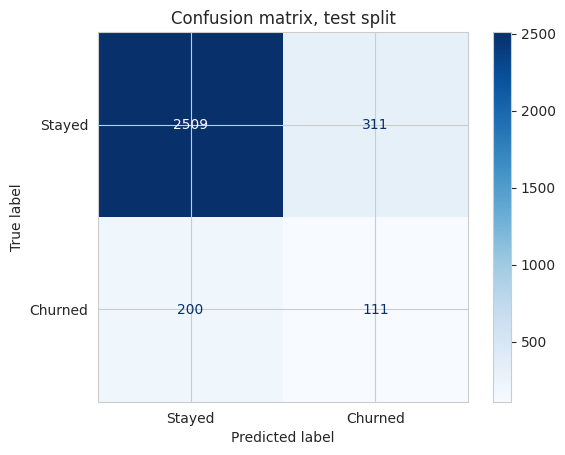

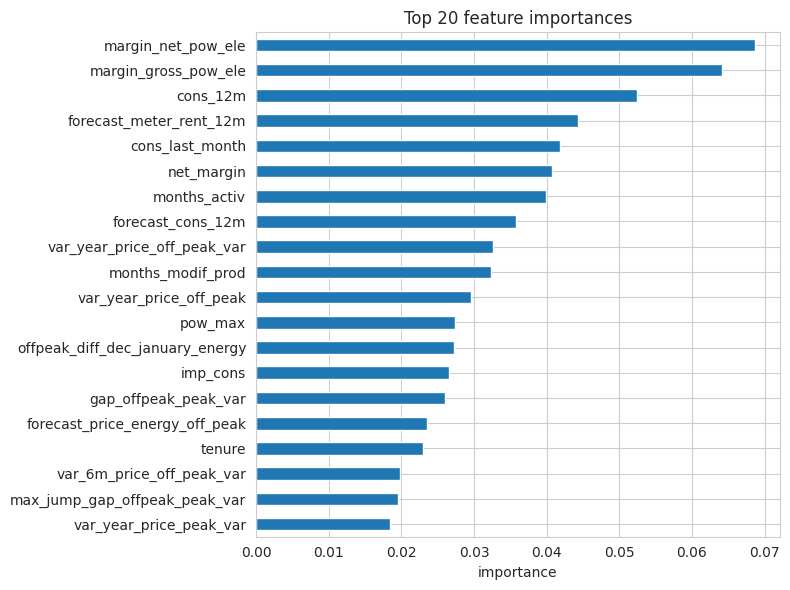

In [79]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, roc_auc_score

X = df.drop(columns=["id", "churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# Cross-validation on the training split only, so the test split is untouched
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "roc_auc"]
cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
print("Five-fold CV on training split (mean ± std):")
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"  {metric:<10} {scores.mean():.3f} ± {scores.std():.3f}")

# Fit on the full training split, then evaluate once on the test split
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\nTest split:")
print(f"  precision {precision_score(y_test, y_pred):.3f}")
print(f"  recall    {recall_score(y_test, y_pred):.3f}")
print(f"  ROC-AUC   {roc_auc_score(y_test, y_proba):.3f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues"
)
plt.title("Confusion matrix, test split")
plt.show()

# Top 20 feature importances
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(20).sort_values().plot.barh(figsize=(8, 6))
plt.title("Top 20 feature importances")
plt.xlabel("importance")
plt.tight_layout()
plt.show()


### 5.1 Reading the results

**Why accuracy is the wrong metric.** About 9.7% of customers churned, so a model that predicts "stays" for everyone scores about 90% accuracy and catches no one. Precision (of the customers flagged, how many actually left) and recall (of the customers who left, how many were flagged) show the trade-off that matters for a retention offer. ROC-AUC measures how well the model ranks churners above non-churners across all thresholds.

**Is it good enough to act on?** Partly. On the held-out test split the model finds 185 of the 355 customers who churned (recall 0.52) at precision 0.20, so for every five customers it flags, one actually leaves. ROC-AUC is 0.70 in cross-validation and on the test split, which is better than chance but modest: the features only partly explain churn. That is good enough to decide who gets a retention call, where a wasted call is cheap and a missed churner is not, but not good enough for anything automatic such as a discount applied without review. The five-fold cross-validation scores sit close to the test scores, so the model is not overfitting.

**Where the price features rank.** The two power margins (`margin_net_pow_ele`, `margin_gross_pow_ele`) are the strongest features, followed by 12-month consumption, meter rent, months active and last-month consumption. The best price feature, the average off-peak to peak gap (`gap_offpeak_peak_var`), is tenth; the December-to-January difference suggested by the team is fourteenth; the maximum monthly jumps sit lower still. Price is a weak contributor, not the driver, which answers PowerCo's hypothesis.



## 6. Findings and recommendations

- **Price sensitivity is not supported as the main driver.** The median forecast off-peak energy price is almost identical for churners (0.1428) and non-churners (0.1432), and the median peak price differs by less than 0.003 (0.0868 vs 0.0839). Average prices barely moved across 2015. A blanket price response would target the wrong problem.
- **Churners are slightly different customers, not cheaper ones.** Churners have a median of 4 years with PowerCo against 5 for customers who stayed, and a slightly higher median net margin (121.86 vs 111.86). PowerCo is losing a little more of its more profitable and newer customers.
- **Recommendation: target retention, don't discount broadly.** Use the classifier to flag high-risk customers and make retention offers only to them, comparing the cost of each offer with the net margin it protects. A discount across the whole base would give away margin on customers who were never at risk.
- **The model confirms it.** Margins, consumption and tenure dominate the feature importances; the best price feature ranks tenth. Price is a weak contributor to churn, not the main cause. Next steps: test the model on a later period to confirm it generalises, get PowerCo's actual cost of a retention offer so the discount-versus-margin trade-off can be worked through, and add customer-level data (service contacts, complaints) that the current tables lack.

*Median differences come from the saved outputs in section 3.7; the sample sizes are large, but these are small gaps and should be read as directional.*
